# Deforestation and lost forest-addition capacity

## Purpose and scope

FRA defines deforestation as the conversion of forest to another land use. For each study unit, the pipeline selects the most recent reported annual area-loss rate among 2020–2025, 2015–2020 and 2010–2015. This notebook examines that reporting coverage and how the selected annual area loss is valued using the unit's mean GCW addition rate per hectare.

The resulting quantity is lost annual capacity to add carbon to living forest biomass. It is not a measurement of carbon already released from forest stocks, and missing FRA reports remain missing rather than being interpreted as zero.

## Load the selected FRA rate and capacity-loss results

The country-level output carries the selected reporting status, annual capacity loss and its value under GSCC. The pipeline uses the latest FRA rate available for each unit, then applies that unit's mean GCW flow per hectare. The rates are not separately observed by biome.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def find_repo_root(start):
    for candidate in (start, *start.parents):
        if (candidate / "code" / "notebooks").is_dir() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the repository from the notebook working directory.")

ROOT = find_repo_root(Path.cwd().resolve())
while ROOT != ROOT.parent and not (ROOT / 'pyproject.toml').is_file():
    ROOT = ROOT.parent
if not (ROOT / 'pyproject.toml').is_file():
    raise FileNotFoundError('Run this notebook from within the repository.')

DATA = ROOT / 'data' / 'derived'
RESULTS = ROOT / 'results'
TABLES = RESULTS / 'tables' / 'manuscript'
VALIDATION = ROOT / 'data' / 'derived' / 'validation'
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)
print(f'Repository: {ROOT}')

Repository: C:\Users\aurel\Desktop\M2\Stage ecoseas-csm\CSM\BNC2 paper\repo


## 2. Separate reporting coverage from positive reported loss

The first summary counts units with an available FRA rate and units with a positive rate. A reported zero is a valid zero; a missing value means that no usable rate is reported in the selected periods. These categories must remain distinct when comparing groups or totals.

In [2]:
accounts = pd.read_csv(TABLES / 'Supplementary_country_level_accounts_2024.csv')
reporter = accounts['reported_deforestation'].fillna(False).astype(bool)
loss = pd.to_numeric(accounts['loss_tco2_mean'], errors='coerce')
print({'all_unit_records':len(accounts), 'reporting_units':int(reporter.sum()), 'positive_loss_units':int((reporter & loss.gt(0)).sum()), 'reported_nonpositive_or_zero':int((reporter & loss.le(0)).sum())})
coverage = accounts.loc[reporter, ['UNIT_CODE', 'name', 'groups', 'reported_deforestation', 'loss_tco2_mean', 'erosion_pct_of_gcw', 'loss_value_usd2015_yr_mean']]
display(coverage.head(20))

{'all_unit_records': 266, 'reporting_units': 139, 'positive_loss_units': 100, 'reported_nonpositive_or_zero': 39}


,UNIT_CODE,name,groups,reported_deforestation,loss_tco2_mean,erosion_pct_of_gcw,loss_value_usd2015_yr_mean
3,AGO,Angola,LDCs,True,1.748833e+06,0.806862,9.785994e+08
8,ARG,Argentina,Developing economies,True,7.068733e+05,0.391770,3.955471e+08
19,AUS,Australia,Developed economies,True,2.175637e+06,0.335021,1.217428e+09
20,AUT,Austria,Developed economies,True,2.689959e+04,0.131407,1.505228e+07
21,AZE,Azerbaijan,Developing economies,True,4.648978e+05,7.394163,2.601442e+08
25,BEL,Belgium,Developed economies,True,1.295166e+04,0.368371,7.247396e+06
26,BEN,Benin,LDCs,True,1.924114e+05,1.792377,1.076682e+08
28,BFA,Burkina Faso,LDCs,True,4.382361e+05,3.951535,2.452250e+08
29,BGD,Bangladesh,LDCs,True,6.232127e+04,1.284468,3.487329e+07
30,BGR,Bulgaria,Developed economies,True,0.000000e+00,0.000000,0.000000e+00


## 3. Compare capacity loss across groups

Table 3 summarizes the selected reporters by economic group. Read each total with its reporting-unit and positive-loss counts. Group medians describe the distribution among reporters; they do not impute the experience of units with missing FRA values.

In [3]:
table3 = pd.read_csv(TABLES / 'Table3_forest_capacity_erosion.csv')
display(table3)
by_group = accounts.loc[reporter].groupby('groups', dropna=False).agg(reporting_units=('UNIT_CODE','size'), positive_loss_units=('loss_tco2_mean',lambda x: int(pd.to_numeric(x,errors='coerce').gt(0).sum())), median_capacity_loss_tco2_yr=('loss_tco2_mean',lambda x: pd.to_numeric(x,errors='coerce').median()), median_erosion_pct=('erosion_pct_of_gcw',lambda x: pd.to_numeric(x,errors='coerce').median())).reset_index()
display(by_group)

,group,reporting_units,positive_loss_units,lost_capacity_mtco2_yr,lost_gcw_billion_usd2015_yr,median_erosion_pct_of_gcw
0,Developed economies,47,30,2.869163,1.605506,0.019853
1,Developing economies,51,36,20.731026,11.600520,0.150520
2,LDCs,24,22,9.403865,5.262148,1.149668
3,SIDS,17,12,0.373345,0.208914,0.068612
4,Unclassified,0,0,NaN,NaN,NaN
5,Total,139,100,33.377400,18.677088,NaN


,groups,reporting_units,positive_loss_units,median_capacity_loss_tco2_yr,median_erosion_pct
0,Developed economies,47,30,2307.177762,0.019853
1,Developing economies,51,36,19501.033850,0.150520
2,LDCs,24,22,175897.421450,1.149668
3,SIDS,17,12,1062.099727,0.068612


### Visual summary: largest estimated annual capacity losses

This chart ranks the largest positive unit-level capacity-loss estimates. It helps identify which observations contribute most to the upper tail; it is not a map of the lost area or a measure of historical emissions.

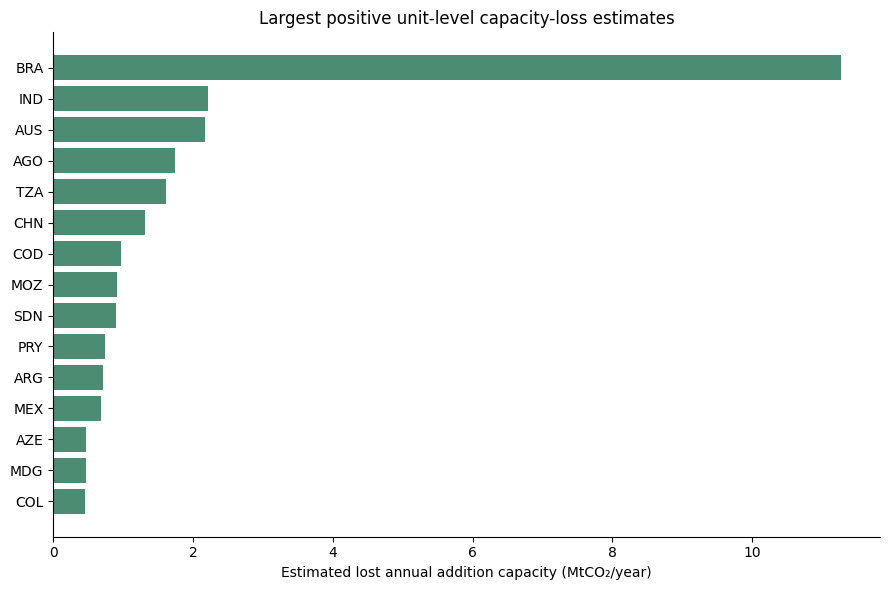

In [4]:
plot_loss = accounts.loc[reporter & loss.gt(0), ["UNIT_CODE", "name", "loss_tco2_mean", "groups"]].copy()
plot_loss["loss_mtco2_yr"] = pd.to_numeric(plot_loss["loss_tco2_mean"], errors="coerce") / 1e6
plot_loss = plot_loss.nlargest(15, "loss_mtco2_yr").sort_values("loss_mtco2_yr")
fig, ax = plt.subplots(figsize=(9, 6))
colors = ["#4C8C72" if pd.notna(group) else "#999999" for group in plot_loss["groups"]]
ax.barh(plot_loss["UNIT_CODE"], plot_loss["loss_mtco2_yr"], color=colors)
ax.set_xlabel("Estimated lost annual addition capacity (MtCO₂/year)")
ax.set_title("Largest positive unit-level capacity-loss estimates")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## 4. Inspect source-period reports and scenario values

The trend table preserves the reported annual rates and their source periods. The scenario table displays the values used by the current calculation. Keep the selected annual loss rate, the resulting capacity estimate and its GSCC valuation separate when reading the numbers.

In [5]:
trend = pd.read_csv(TABLES / 'Supplementary_deforestation_trend.csv')
scenarios = pd.read_csv(TABLES / 'Supplementary_deforestation_scenarios.csv')
display(trend)
display(scenarios)

,fra_interval,reported_deforestation_kha_per_year,midpoint_year,reported_deforestation_mha_per_year
0,1990-2000,15818.77,1995.0,15.81877
1,2000-2010,13328.62,2005.0,13.32862
2,2010-2015,9878.10,2012.5,9.87810
3,2015-2020,9477.81,2017.5,9.47781
4,2020-2025,8484.25,2022.5,8.48425


,metric,value,unit,assumption_or_formula,discount_rate,our_allocation_rate
0,Current annual lost forest addition capacity,33.377400,MtCO2/yr,Sum of reported-unit estimates; 139 reporting ...,NaN,NaN
1,Ten-year cumulative capacity not supplied,0.333774,GtCO2 over 10 years,Current annual loss repeats for 10 years; no r...,NaN,NaN
2,Current annual lost capacity relative to curre...,0.226075,% of current annual forest additions,Annual lost capacity / global annual forest ad...,NaN,NaN
3,Current annual lost GCW value,18.677088,billion US$2015/yr,Sum of reported-unit annual lost GCW estimates,NaN,NaN
4,Perpetuity value of annual lost GCW at 2% disc...,0.933854,trillion US$2015,Annual lost GCW value / 0.02; perpetual consta...,0.02,NaN


## 5. Trace the largest unit-level cases

The ranked table retains study-unit identifiers and group labels so the largest estimates can be traced to their reported rates and account inputs. A large capacity-loss estimate can reflect a large area-loss rate, a high GCW addition rate per hectare, or both.

In [6]:
positive = accounts.loc[reporter & loss.gt(0), ['UNIT_CODE', 'name', 'region', 'groups', 'loss_tco2_mean', 'erosion_pct_of_gcw', 'loss_value_usd2015_yr_mean']].copy()
display(positive.sort_values('loss_tco2_mean', ascending=False).head(20))

,UNIT_CODE,name,region,groups,loss_tco2_mean,erosion_pct_of_gcw,loss_value_usd2015_yr_mean
39,BRA,Brazil,Americas,Developing economies,1.126536e+07,0.671777,6.303788e+09
114,IND,India,Asia,Developing economies,2.218650e+06,0.814010,1.241496e+09
19,AUS,Australia,Oceania,Developed economies,2.175637e+06,0.335021,1.217428e+09
3,AGO,Angola,Africa,LDCs,1.748833e+06,0.806862,9.785994e+08
240,TZA,United Republic of Tanzania,Africa,LDCs,1.606854e+06,1.084596,8.991520e+08
50,CHN,"China (incl. Taiwan, Hong Kong SAR and Macao SAR)",Asia,Developing economies,1.315226e+06,0.120624,7.359646e+08
53,COD,Democratic Republic of the Congo,Africa,LDCs,9.713073e+05,0.203680,5.435172e+08
161,MOZ,Mozambique,Africa,LDCs,9.148790e+05,0.835643,5.119415e+08
204,SDN,Sudan,Africa,LDCs,9.044978e+05,1.201070,5.061324e+08
193,PRY,Paraguay,Americas,Developing economies,7.455940e+05,1.522096,4.172142e+08
